## NAME: MALIK MUHAMMAD ALI HAIDER
## ROLL NUMBER: SP23-BBD-030
## CLASS: BBD 8A (BDS 6)
## SUBJECT: MGT389 NLP FOR BUSINESS / AIC365 NLP
## TOPIC: Lab 06-Tasks
## Submitted to: Sir Zaeem Akbar (zaeemakbar.khan@comsats.edu.pk)

### **Activity 1**: Using the provided app review dataset, build a full sklearn Pipeline (TF-IDF + your choice of Naive Bayes or Logistic Regression). Train it, then report accuracy, precision, recall, and Fl-score on a held-out test split.

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

In [34]:
df = pd.read_csv("app_store_reviews.csv", sep=None, engine="python")
print(df.shape); print(df.columns.tolist()); print(df.head())

(321, 10)
['date', 'platform', 'country', 'review', 'star', 'user_id', 'issue_flag', 'likes_count', 'dislike_count', 'label']
         date platform    country  \
0   7.07.2023      iOS  Australia   
1  12.08.2023  Android      India   
2  12.09.2023      iOS         UK   
3  12.07.2023  Android     Brazil   
4  24.09.2023      iOS      India   

                                              review  star  \
0  Love the itinerary sharing feature. It makes p...     5   
1  The premium price is a bit high, but the featu...     4   
2  I can't share my trip details via WhatsApp dir...     5   
3  The price of premium is too high, could be bet...     3   
4                         Smooth booking experience.     3   

                                user_id issue_flag  likes_count  \
0  13c95471-be12-42f6-95d1-fa3dd104909b         No            1   
1  945725ef-7277-4884-b717-9259af1df8d2         No            2   
2  e3d956b8-6e00-4099-84ca-f51406e6b3f7         No            5   
3  1fa559f

In [37]:
df = pd.read_csv("app_store_reviews.csv", sep=";")      # semicolon-separated file
df = df.rename(columns={"review": "text"})
df = df.dropna(subset=["text", "star"])
df = df.drop_duplicates(subset="text")                  # avoid the same review in train and test
df = df[df["star"] != 3].copy()                         # drop neutral 3-star reviews
df["label"] = df["star"].apply(lambda r: "positive" if r >= 4 else "negative")
print(df.shape)
print(df["label"].value_counts())

(219, 10)
label
positive    115
negative    104
Name: count, dtype: int64


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"])

pipe = Pipeline([("tfidf", TfidfVectorizer()),
                 ("clf", LogisticRegression(max_iter=1000))])
pipe.fit(X_train, y_train)
preds = pipe.predict(X_test)

print(f"Accuracy : {accuracy_score(y_test, preds):.4f}")
print(f"Precision: {precision_score(y_test, preds, pos_label='positive'):.4f}")
print(f"Recall   : {recall_score(y_test, preds, pos_label='positive'):.4f}")
print(f"F1-Score : {f1_score(y_test, preds, pos_label='positive'):.4f}")

Accuracy : 0.6818
Precision: 0.6957
Recall   : 0.6957
F1-Score : 0.6957


### **Activity 2**: On the same app review dataset, plot the confusion matrix for your trained model. In 3-4 sentences, explain what the matrix reveals about which class the model struggles with most.

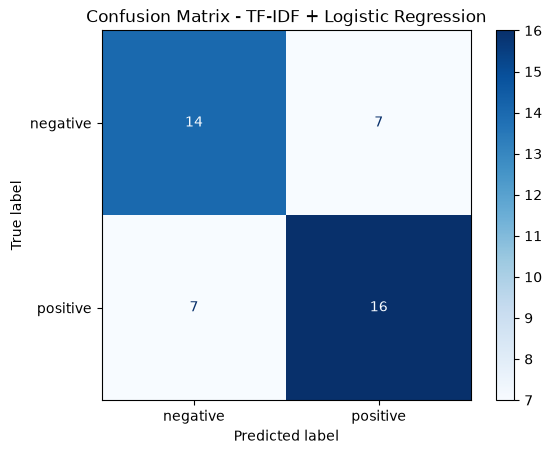

In [41]:
labels = ["negative", "positive"]
cm = confusion_matrix(y_test, preds, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Confusion Matrix - TF-IDF + Logistic Regression")
plt.show()

In [51]:
print(cm)
print(f"Negative recall = {cm[0,0] / cm[0].sum():.2f}, positive recall = {cm[1,1] / cm[1].sum():.2f}")

[[14  7]
 [ 7 16]]
Negative recall = 0.67, positive recall = 0.70


##### The confusion matrix shows that the model makes mistakes on both classes at almost the same rate. Of the 21 negative reviews in the test set it classified 14 correctly and wrongly labelled 7 as positive, and of the 23 positive reviews it classified 16 correctly and wrongly labelled 7 as negative. This gives a recall of about 0.67 for the negative class and 0.70 for the positive class, so the model struggles slightly more with negative reviews, but the difference is small and it shows no strong bias toward either class. Some of these errors may come from noisy labels, since the star ratings used to create the classes do not always match the review text, and with only 44 test reviews a few mistakes change the results noticeably.

### **Activity 3**: Write code to programmatically build a DataFrame of every misclassified example from your test set, with columns text, true_label, predicted_label, and predicted_probability (use .predict_proba()). Sort this DataFrame by predicted_probability in descending order and print the top 5 rows. These are the cases where your model was most confident and still wrong.

In [43]:
proba = pipe.predict_proba(X_test)
errors = pd.DataFrame({
    "text": X_test.values,
    "true_label": y_test.values,
    "predicted_label": preds,
    "predicted_probability": proba.max(axis=1),    # confidence in the predicted class
})
errors = errors[errors["true_label"] != errors["predicted_label"]]
print("Misclassified examples:", len(errors))

Misclassified examples: 14


In [44]:
errors = errors.sort_values("predicted_probability", ascending=False)
print(errors.head(5).to_string(index=False))

                                                                    text true_label predicted_label  predicted_probability
        The user interface is confusing, I can't figure out basic tasks.   negative        positive               0.608145
Update brought in some handy features, especially for tracking expenses.   negative        positive               0.586134
                                               Simple and user-friendly.   negative        positive               0.585957
                                                  Slow customer support.   negative        positive               0.570157
                                              Search results inaccurate.   negative        positive               0.566005


### **Activity 04**: Write code to compute the class distribution of the app review dataset using .value_counts(). Then retrain your pipeline with class balancing applied (use class_weight='balanced' for Logistic Regression, or sklearn.utils.resample to oversample the minority class before training). Print a side-by-side comparison of precision, recall, and F1 for the negative class from your original model (Activity 1) versus this rebalanced model.

In [45]:
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

label
positive    115
negative    104
Name: count, dtype: int64
label
positive    0.525
negative    0.475
Name: proportion, dtype: float64


In [46]:
pipe_bal = Pipeline([("tfidf", TfidfVectorizer()),
                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
pipe_bal.fit(X_train, y_train)
preds_bal = pipe_bal.predict(X_test)

In [47]:
def neg_scores(y_true, y_pred):
    return (precision_score(y_true, y_pred, pos_label="negative"),
            recall_score(y_true, y_pred, pos_label="negative"),
            f1_score(y_true, y_pred, pos_label="negative"))

comparison = pd.DataFrame(
    [neg_scores(y_test, preds), neg_scores(y_test, preds_bal)],
    index=["Original", "Balanced (class_weight)"],
    columns=["Precision (neg)", "Recall (neg)", "F1 (neg)"]).round(4)
print(comparison)

                         Precision (neg)  Recall (neg)  F1 (neg)
Original                          0.6667        0.6667    0.6667
Balanced (class_weight)           0.6957        0.7619    0.7273


### **Activity 05**: A small business wants to auto-flag negative app reviews for their support team to respond to first. Using your trained pipeline from Activity 1, run it on the new unseen customer feedback snippets provided below, list which ones get flagged as negative, and write a short (3-4 sentence) recommendation to the business on how reliable this auto-flagging is, based on your model’s precision and recall for the negative class.

In [48]:
snippets = [                      
    "The app crashes every time I open it",
    "Love the new design, very smooth",
    "Too many ads, I want a refund",
    "Works great and easy to use",
    "Cannot login, support is useless",
]
snip_preds = pipe.predict(snippets)
neg_col = list(pipe.classes_).index("negative")
snip_neg_prob = pipe.predict_proba(snippets)[:, neg_col]
for s, p, pr in zip(snippets, snip_preds, snip_neg_prob):
    print(f"{p:<9} P(neg)={pr:.2f}  {s}")

negative  P(neg)=0.65  The app crashes every time I open it
positive  P(neg)=0.43  Love the new design, very smooth
negative  P(neg)=0.64  Too many ads, I want a refund
positive  P(neg)=0.40  Works great and easy to use
negative  P(neg)=0.53  Cannot login, support is useless


In [49]:
print("Flagged as negative:")
for s, p in zip(snippets, snip_preds):
    if p == "negative":
        print(" -", s)

Flagged as negative:
 - The app crashes every time I open it
 - Too many ads, I want a refund
 - Cannot login, support is useless


In [50]:
p_neg, r_neg, f_neg = neg_scores(y_test, preds)
print(f"Negative-class precision = {p_neg:.2f}, recall = {r_neg:.2f}")

Negative-class precision = 0.67, recall = 0.67
